# Task 1A – Mô hình camera, hiệu chuẩn (calibration) và sửa méo (undistortion)

**FCVG101 – FruitSort Vision Assistant · Task 1: Core Image Analysis Engine**

Mục tiêu của notebook:

1. Phát hiện các góc trong của bàn cờ trên ảnh chụp **thật** từ cùng một điện thoại.
2. **Tự cài phương pháp Zhang** (DLT chuẩn hoá → nghiệm dạng đóng của K → tham số ngoại → tối ưu Levenberg–Marquardt) rồi **so sánh với `cv2.calibrateCamera`**.
3. Đánh giá bằng **reprojection error** (theo pixel), phát hiện ảnh bất thường.
4. **Chọn mô hình méo ống kính bằng cross-validation**: so lỗi trên những ảnh *không* dùng để calibrate, thay vì chỉ nhìn RMS trên tập huấn luyện.
5. Phân tích **độ bất định** của K và độ ổn định theo số ảnh.
6. **Sửa méo** ảnh kiểm tra và **đo định lượng độ thẳng** của các đường thẳng trước và sau khi sửa.
7. Lưu `artifacts/calibration.npz` để app ở Task 3 dùng lại.

## 1. Mô hình camera

**Pinhole.** Một điểm 3-D $(X, Y, Z)$ trong hệ toạ độ camera được chiếu lên mặt phẳng ảnh chuẩn hoá:
$x = X/Z,\; y = Y/Z$. Ma trận nội tại $K$ đổi sang pixel:

$$
\begin{bmatrix}u\\v\\1\end{bmatrix} = K\begin{bmatrix}x\\y\\1\end{bmatrix},\qquad
K=\begin{bmatrix}f_x & 0 & c_x\\ 0 & f_y & c_y\\ 0&0&1\end{bmatrix}
$$

Điểm trên bàn cờ (hệ toạ độ thế giới, $Z_w=0$) được đưa về hệ camera bằng tham số ngoại $[R\,|\,t]$ của từng ảnh.

**Méo ống kính Brown–Conrady** (cùng mô hình OpenCV dùng), với $r^2 = x^2+y^2$:

$$
x_d = x(1+k_1r^2+k_2r^4+k_3r^6) + 2p_1xy + p_2(r^2+2x^2),\qquad
y_d = y(1+k_1r^2+k_2r^4+k_3r^6) + p_1(r^2+2y^2) + 2p_2xy
$$

$k_1,k_2,k_3$ là méo xuyên tâm (radial), $p_1,p_2$ là méo tiếp tuyến (tangential). Ở mục 5, số hệ số này được **chọn bằng dữ liệu**.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

ROOT = Path.cwd()                      # mở notebook từ thư mục task1/
sys.path.insert(0, str(ROOT))
from src import calibration as cal

DATA = ROOT.parent / 'datasets' / 'checkerboard'
CALIB_DIR = DATA / 'calibration'                  # ảnh bàn cờ, cùng một điện thoại
SAMPLE_IMG = DATA / 'mau' / '20261021_162828.jpg' # ảnh kiểm tra, KHÔNG dùng để calibrate
LINES_IMG = DATA / 'check_test.jpg'               # ảnh sàn gạch có nhiều đường thẳng

PATTERN = (9, 6)    # số GÓC TRONG (cột, hàng) -> bàn cờ 10 x 7 ô
SQUARE_MM = 18.0    # cạnh một ô (mm). Bàn cờ hiển thị trên màn hình: hãy đo lại bằng thước.
                    # Giá trị này chỉ ảnh hưởng đơn vị của t (tịnh tiến), KHÔNG ảnh hưởng K hay dist.
OUT = ROOT / 'results' / '1A'
OUT.mkdir(parents=True, exist_ok=True)
ARTIFACT = ROOT / 'artifacts' / 'calibration.npz'

plt.rcParams.update({'figure.dpi': 90, 'savefig.dpi': 110})
pd.set_option('display.float_format', lambda v: f'{v:.6g}')

def save(fig, name):
    fig.savefig(OUT / name, bbox_inches='tight')
    plt.show()

def rgb(img, width=None):
    if width:
        img = cv2.resize(img, (width, int(img.shape[0] * width / img.shape[1])), interpolation=cv2.INTER_AREA)
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

np.set_printoptions(suppress=True, precision=4)
print('OpenCV', cv2.__version__, '| NumPy', np.__version__)

OpenCV 5.0.0 | NumPy 2.5.4


## 2. Phát hiện góc trong của bàn cờ

Ảnh gốc 12 MP (4000×3000). Để nhanh và bền với hiện tượng **moiré** (vân giao thoa khi chụp màn hình), góc được tìm bằng `findChessboardCornersSB` trên ảnh thu nhỏ còn 1200 px, sau đó **tinh chỉnh dưới pixel bằng `cornerSubPix` trên ảnh gốc** (xem `src/calibration.py::detect_corners`).

In [2]:
paths = cal.list_images(CALIB_DIR)
data = cal.collect_correspondences(paths, PATTERN, SQUARE_MM)
log = pd.DataFrame(data.log)
log.to_csv(OUT / 'detection_log.csv', index=False)
W, H = data.image_size
print(f'Ảnh hợp lệ: {data.n_views}/{len(paths)} | kích thước ảnh: {W} x {H} px | '
      f'{len(data.object_points[0])} góc mỗi ảnh -> {data.n_views * len(data.object_points[0])} cặp điểm 3D-2D')
log

Ảnh hợp lệ: 15/15 | kích thước ảnh: 4000 x 3000 px | 54 góc mỗi ảnh -> 810 cặp điểm 3D-2D


,file,status,detector
0,20261021_152727.jpg,ACCEPTED,SB + subpixel
1,20261021_152733.jpg,ACCEPTED,SB + subpixel
2,20261021_152736.jpg,ACCEPTED,SB + subpixel
3,20261021_152807.jpg,ACCEPTED,SB + subpixel
4,20261021_152812.jpg,ACCEPTED,SB + subpixel
5,20261021_152816.jpg,ACCEPTED,SB + subpixel
6,20261021_152823.jpg,ACCEPTED,SB + subpixel
7,20261021_152856.jpg,ACCEPTED,SB + subpixel
8,20261021_152859.jpg,ACCEPTED,SB + subpixel
9,20261021_152902.jpg,ACCEPTED,SB + subpixel


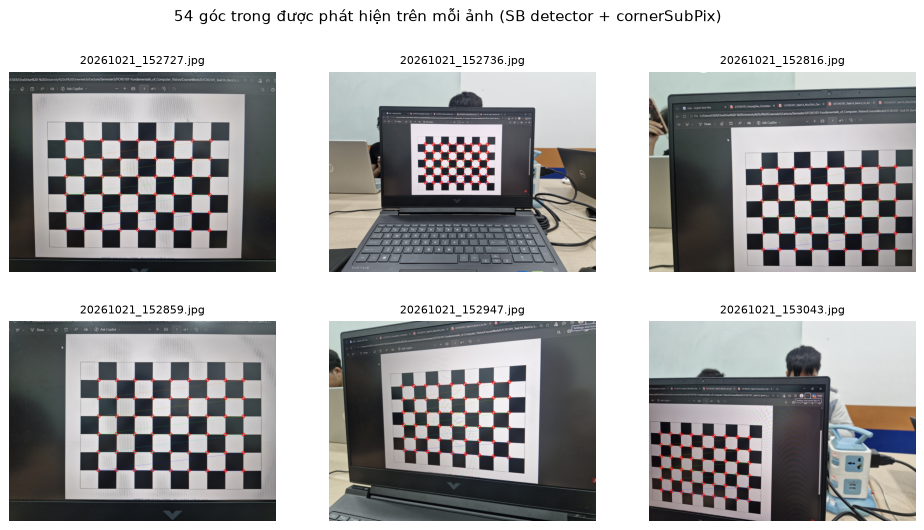

In [3]:
show = np.linspace(0, data.n_views - 1, 6).astype(int)
fig, axes = plt.subplots(2, 3, figsize=(13, 6.6))
for ax, i in zip(axes.ravel(), show):
    img = cv2.imread(str(data.accepted[i]))
    cv2.drawChessboardCorners(img, PATTERN, data.image_points[i], True)
    for p in data.image_points[i].reshape(-1, 2):
        cv2.circle(img, (int(p[0]), int(p[1])), 22, (0, 0, 255), 8)
    ax.imshow(rgb(img, 800)); ax.set_title(data.accepted[i].name, fontsize=9); ax.axis('off')
fig.suptitle('54 góc trong được phát hiện trên mỗi ảnh (SB detector + cornerSubPix)')
save(fig, 'corners_overlay.png')

**Độ phủ khung hình.** Méo ống kính lớn nhất ở **mép ảnh**. Nếu không có góc nào nằm gần mép thì hệ số méo được ước lượng kém (mô hình phải *ngoại suy*). Biểu đồ dưới cho biết dữ liệu đã phủ khung hình đến đâu.

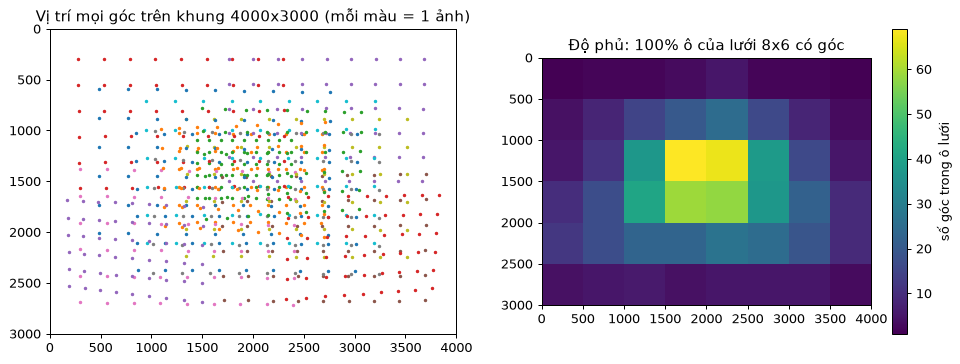

Bán kính chuẩn hoá xa nhất mà dữ liệu đạt tới: 0.84 (1.0 = góc ảnh)


In [4]:
allpts = np.concatenate([p.reshape(-1, 2) for p in data.image_points])
GX, GY = 8, 6
hist, _, _ = np.histogram2d(allpts[:, 0], allpts[:, 1], bins=[GX, GY], range=[[0, W], [0, H]])
coverage = (hist > 0).mean()
r_norm = np.hypot(allpts[:, 0] - W / 2, allpts[:, 1] - H / 2) / np.hypot(W / 2, H / 2)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
for p in data.image_points:
    p = p.reshape(-1, 2); ax[0].scatter(p[:, 0], p[:, 1], s=3)
ax[0].set_xlim(0, W); ax[0].set_ylim(H, 0); ax[0].set_aspect('equal')
ax[0].set_title('Vị trí mọi góc trên khung 4000x3000 (mỗi màu = 1 ảnh)')
im = ax[1].imshow(hist.T, cmap='viridis', extent=[0, W, H, 0])
plt.colorbar(im, ax=ax[1], label='số góc trong ô lưới')
ax[1].set_title(f'Độ phủ: {coverage:.0%} ô của lưới {GX}x{GY} có góc')
save(fig, 'corner_coverage.png')
print(f'Bán kính chuẩn hoá xa nhất mà dữ liệu đạt tới: {r_norm.max():.2f} (1.0 = góc ảnh)')

## 3. Phương pháp Zhang – tự cài đặt

Toàn bộ nằm trong `src/calibration.py`, chỉ dùng NumPy (SVD) và SciPy (`least_squares`):

| Bước | Hàm | Ý tưởng |
|---|---|---|
| 1 | `homography_dlt` | Bàn cờ phẳng ⇒ ảnh của nó là một **homography** $H = K[r_1\; r_2\; t]$. Giải $Ah=0$ bằng SVD, có **chuẩn hoá Hartley** để ổn định số học. |
| 2 | `intrinsics_from_homographies` | $r_1 \perp r_2$ và $\lVert r_1\rVert=\lVert r_2\rVert$ cho 2 phương trình tuyến tính/ảnh theo $B = K^{-T}K^{-1}$ ⇒ SVD ⇒ **K dạng đóng**. |
| 3 | `extrinsics_from_homography` | $r_1 = \lambda K^{-1}h_1,\ r_2=\lambda K^{-1}h_2,\ r_3 = r_1\times r_2,\ t=\lambda K^{-1}h_3$, rồi ép $R$ về ma trận quay gần nhất (SVD). |
| 4 | `calibrate_zhang` | **Levenberg–Marquardt** cực tiểu tổng bình phương reprojection error theo $K$, 5 hệ số méo và mọi $(R,t)$. |

**Bước 1 trên một ảnh:**

In [5]:
i = 0
obj_xy = data.object_points[i][:, :2].astype(float)
img_xy = data.image_points[i].reshape(-1, 2).astype(float)
H_mine = cal.homography_dlt(obj_xy, img_xy)
H_cv, _ = cv2.findHomography(obj_xy, img_xy, 0)          # 0 = bình phương tối thiểu, không RANSAC
p_mine = cv2.perspectiveTransform(obj_xy.reshape(-1, 1, 2), H_mine).reshape(-1, 2)
p_cv = cv2.perspectiveTransform(obj_xy.reshape(-1, 1, 2), H_cv).reshape(-1, 2)
print('H tự cài (H33 = 1):\n', np.round(H_mine, 4))
print(f'Điểm chiếu bằng H tự cài vs bằng cv2.findHomography lệch nhau tối đa: {np.abs(p_mine - p_cv).max():.4f} px')
print(f'Sai số chiếu lại chỉ với homography (chưa mô hình hoá méo): {np.linalg.norm(p_mine - img_xy, axis=1).mean():.3f} px')

H tự cài (H33 = 1):
 [[  15.0363    0.2759  853.3424]
 [   0.0359   15.2684 1032.1896]
 [  -0.        0.0002    1.    ]]
Điểm chiếu bằng H tự cài vs bằng cv2.findHomography lệch nhau tối đa: 0.0150 px
Sai số chiếu lại chỉ với homography (chưa mô hình hoá méo): 2.208 px


**Bước 2 → 4 và so sánh với OpenCV:**

In [6]:
z = cal.calibrate_zhang(data.object_points, data.image_points, n_dist=5)
ocv = cal.calibrate_opencv(data.object_points, data.image_points, data.image_size)

def row(name, K, dist, rms):
    d = np.zeros(5); d[:5] = np.ravel(dist)[:5]
    return dict(method=name, fx=K[0, 0], fy=K[1, 1], cx=K[0, 2], cy=K[1, 2],
                k1=d[0], k2=d[1], p1=d[2], p2=d[3], k3=d[4], rms_px=rms)

cmp = pd.DataFrame([
    row('Zhang tự cài: nghiệm dạng đóng (bước 2, chưa có méo)', z['K_closed_form'], np.zeros(5), z['rms_closed_form']),
    row('Zhang tự cài: sau tối ưu LM (bước 4)', z['K'], z['dist'], z['rms']),
    row('OpenCV cv2.calibrateCamera', ocv['K'], ocv['dist'], ocv['rms']),
]).set_index('method')
cmp.to_csv(OUT / 'zhang_vs_opencv.csv')
rel = ((cmp.iloc[1][['fx', 'fy', 'cx', 'cy']] - cmp.iloc[2][['fx', 'fy', 'cx', 'cy']]).abs()
       / cmp.iloc[2][['fx', 'fy', 'cx', 'cy']])
print(f"LM hội tụ: {z['success']} sau {z['n_iterations']} lần đánh giá hàm")
print('Chênh lệch tương đối fx, fy, cx, cy giữa bản tự cài và OpenCV:', ', '.join(f'{v:.1e}' for v in rel))
cmp

LM hội tụ: True sau 6 lần đánh giá hàm
Chênh lệch tương đối fx, fy, cx, cy giữa bản tự cài và OpenCV: 2.3e-08, 2.3e-08, 1.4e-09, 2.2e-08


,fx,fy,cx,cy,k1,k2,p1,p2,k3,rms_px
method,,,,,,,,,,
"Zhang tự cài: nghiệm dạng đóng (bước 2, chưa có méo)",2822.79,2820.44,1982.32,1532.78,0,0,0,0,0,3.50483
Zhang tự cài: sau tối ưu LM (bước 4),2767.21,2767.45,1992.98,1479.67,0.143155,-0.425968,-0.00027712,-0.000378408,0.360174,0.507861
OpenCV cv2.calibrateCamera,2767.21,2767.45,1992.98,1479.67,0.143155,-0.425968,-0.00027712,-0.000378407,0.360173,0.507861


**Đọc bảng:**

- Dòng 1: nghiệm dạng đóng **chưa tính méo** nên RMS còn lớn. Đây chỉ là điểm khởi đầu cho bước tối ưu.
- Dòng 2: sau tối ưu LM, kết quả tự cài **trùng với OpenCV**. Chênh lệch tương đối ở mức sai số làm tròn, cho thấy cài đặt đúng.
- OpenCV cũng dùng đúng chuỗi bước này: khởi tạo bằng homography rồi tối ưu Levenberg–Marquardt.

## 4. Reprojection error

Với mỗi góc, chiếu lại điểm 3-D bằng $K$, dist, $R$, $t$ đã ước lượng (`cv2.projectPoints`), rồi đo **khoảng cách Euclid** (pixel) tới góc đã phát hiện. RMS của `calibrateCamera` chính là $\sqrt{\tfrac{1}{N}\sum e_i^2}$ trên mọi góc.

RMS: 0.5079 px | trung bình: 0.4216 px | median: 0.3600 px | lớn nhất: 2.1290 px  (trên ảnh 4000x3000)


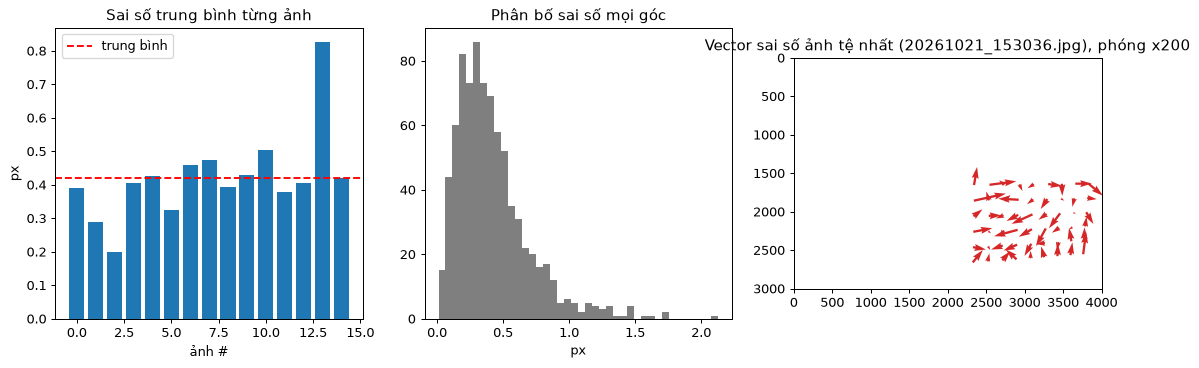

In [7]:
errs = cal.reprojection_errors(data.object_points, data.image_points, ocv['K'], ocv['dist'], ocv['rvecs'], ocv['tvecs'])
view_df = pd.DataFrame({'file': [p.name for p in data.accepted],
                        'mean_err_px': [e.mean() for e in errs],
                        'rms_err_px': [np.sqrt((e ** 2).mean()) for e in errs],
                        'max_err_px': [e.max() for e in errs]})
view_df.to_csv(OUT / 'view_errors.csv', index=False)
all_e = np.concatenate(errs)
print(f"RMS: {ocv['rms']:.4f} px | trung bình: {all_e.mean():.4f} px | median: {np.median(all_e):.4f} px | "
      f"lớn nhất: {all_e.max():.4f} px  (trên ảnh {W}x{H})")

worst = int(view_df.mean_err_px.idxmax())
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
ax[0].bar(range(len(view_df)), view_df.mean_err_px, color='tab:blue')
ax[0].axhline(all_e.mean(), color='r', ls='--', label='trung bình')
ax[0].set_xlabel('ảnh #'); ax[0].set_ylabel('px'); ax[0].set_title('Sai số trung bình từng ảnh'); ax[0].legend()
ax[1].hist(all_e, bins=40, color='tab:gray'); ax[1].set_xlabel('px'); ax[1].set_title('Phân bố sai số mọi góc')
proj, _ = cv2.projectPoints(data.object_points[worst], ocv['rvecs'][worst], ocv['tvecs'][worst], ocv['K'], ocv['dist'])
obs = data.image_points[worst].reshape(-1, 2); res = obs - proj.reshape(-1, 2)
ax[2].quiver(obs[:, 0], obs[:, 1], res[:, 0], -res[:, 1], angles='xy', scale_units='xy', scale=0.005, color='tab:red')
ax[2].set_xlim(0, W); ax[2].set_ylim(H, 0); ax[2].set_aspect('equal')
ax[2].set_title(f'Vector sai số ảnh tệ nhất ({view_df.file[worst]}), phóng x200')
save(fig, 'reprojection_error.png')

In [8]:
thr = 2 * view_df.mean_err_px.median()
bad = view_df.index[view_df.mean_err_px > thr].tolist()
print(f'Ngưỡng ảnh bất thường = 2 x median = {thr:.3f} px -> ảnh bị loại:', [view_df.file[j] for j in bad] or 'không có')
keep = [j for j in range(data.n_views) if j not in bad]
obj_k = [data.object_points[j] for j in keep]
img_k = [data.image_points[j] for j in keep]
files_k = [data.accepted[j].name for j in keep]
if bad:
    r2 = cal.calibrate_opencv(obj_k, img_k, data.image_size)
    print(f"RMS trước khi loại: {ocv['rms']:.4f} px -> sau khi loại: {r2['rms']:.4f} px")
print('Số ảnh dùng cho các bước tiếp theo:', len(keep))

Ngưỡng ảnh bất thường = 2 x median = 0.812 px -> ảnh bị loại: ['20261021_153036.jpg']
RMS trước khi loại: 0.5079 px -> sau khi loại: 0.4581 px
Số ảnh dùng cho các bước tiếp theo: 14


## 5. Chọn mô hình méo bằng cross-validation

RMS trên chính các ảnh đã dùng để calibrate **luôn giảm** khi thêm tham số, kể cả khi mô hình chỉ đang "học thuộc" nhiễu (overfitting). Vì vậy notebook dùng **leave-one-view-out**:

1. Bỏ ra 1 ảnh, calibrate trên các ảnh còn lại.
2. Với ảnh bị bỏ ra: giữ nguyên $K$ và dist, chỉ ước lượng tư thế bằng `solvePnP`, rồi đo reprojection error.
3. Lặp lại cho mọi ảnh và mọi mô hình: 0 hệ số (pinhole thuần), $k_1$; $k_1,k_2$; thêm $p_1,p_2$; thêm $k_3$; rational 8 hệ số.

**Quy tắc chọn:** lấy mô hình **đơn giản nhất** có lỗi hold-out không quá 5 % so với mô hình tốt nhất.

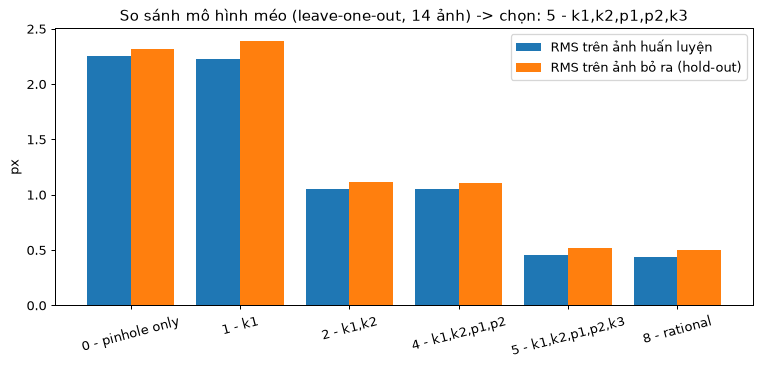

,free_dist_coeffs,train_rms_px,holdout_rms_px,holdout_mean_px,chosen
model,,,,,
0 - pinhole only,0,2.25885,2.31701,1.97148,
1 - k1,1,2.22435,2.38623,1.99532,
"2 - k1,k2",2,1.05386,1.11248,0.895513,
"4 - k1,k2,p1,p2",4,1.04954,1.10982,0.888737,
"5 - k1,k2,p1,p2,k3",5,0.456388,0.518929,0.434338,<==
8 - rational,8,0.435092,0.49988,0.416997,


In [9]:
cvdf = pd.DataFrame(cal.cross_validate_models(obj_k, img_k, data.image_size)).set_index('model')
best = cvdf.holdout_rms_px.min()
choice = cvdf[cvdf.holdout_rms_px <= 1.05 * best].sort_values('free_dist_coeffs').index[0]
cvdf['chosen'] = np.where(cvdf.index == choice, '<==', '')
cvdf.to_csv(OUT / 'distortion_model_cv.csv')

fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(cvdf))
ax.bar(x - 0.2, cvdf.train_rms_px, 0.4, label='RMS trên ảnh huấn luyện')
ax.bar(x + 0.2, cvdf.holdout_rms_px, 0.4, label='RMS trên ảnh bỏ ra (hold-out)')
ax.set_xticks(x, cvdf.index, rotation=15); ax.set_ylabel('px'); ax.legend()
ax.set_title(f'So sánh mô hình méo (leave-one-out, {len(obj_k)} ảnh) -> chọn: {choice}')
save(fig, 'distortion_model_cv.png')
cvdf

**Đọc biểu đồ:**

- Khoảng cách giữa hai cột của mỗi mô hình là **mức overfitting**.
- Mô hình được chọn là mô hình mà thêm tham số nữa **không còn giảm đáng kể lỗi trên ảnh mới**.
- Nếu hold-out giảm mạnh khi thêm $k_3$, ống kính có méo bậc cao. Điều này thường gặp ở camera điện thoại góc rộng, vốn đã được bộ xử lý ảnh (ISP) bù méo một phần.

**Calibration cuối cùng** với mô hình đã chọn, kèm độ lệch chuẩn của từng tham số (`calibrateCameraExtended`):

In [10]:
flags, n_free = cal.DISTORTION_MODELS[choice]
final = cal.calibrate_opencv(obj_k, img_k, data.image_size, flags)
K, dist = final['K'], final['dist']
names = ['fx', 'fy', 'cx', 'cy', 'k1', 'k2', 'p1', 'p2', 'k3', 'k4', 'k5', 'k6']
vals = np.r_[K[0, 0], K[1, 1], K[0, 2], K[1, 2], dist][:len(names)]
std = final['std_intrinsics'][:len(vals)]
unc = pd.DataFrame({'value': vals, 'std': std, 'CI95_low': vals - 1.96 * std, 'CI95_high': vals + 1.96 * std},
                   index=names[:len(vals)])
unc = unc[(unc['std'] > 0) | unc.index.isin(['fx', 'fy', 'cx', 'cy'])]
unc.to_csv(OUT / 'final_parameters.csv')
print('Mô hình:', choice, '| RMS:', round(final['rms'], 4), 'px')
print('K =\n', np.round(K, 3))
print('dist =', np.round(dist, 6))
fov_x = 2 * np.degrees(np.arctan(W / (2 * K[0, 0])))
fov_y = 2 * np.degrees(np.arctan(H / (2 * K[1, 1])))
print(f'Góc nhìn suy ra từ K: ngang {fov_x:.1f}°, dọc {fov_y:.1f}° | lệch tâm quang học so với tâm ảnh: '
      f'({K[0, 2] - W / 2:+.1f}, {K[1, 2] - H / 2:+.1f}) px')
unc

Mô hình: 5 - k1,k2,p1,p2,k3 | RMS: 0.4581 px
K =
 [[2754.646    0.    1995.503]
 [   0.    2754.79  1478.778]
 [   0.       0.       1.   ]]
dist = [ 0.1438 -0.4284 -0.0003 -0.0003  0.3594]
Góc nhìn suy ra từ K: ngang 72.0°, dọc 57.1° | lệch tâm quang học so với tâm ảnh: (-4.5, -21.2) px


,value,std,CI95_low,CI95_high
fx,2754.65,5.80987,2743.26,2766.03
fy,2754.79,5.77362,2743.47,2766.11
cx,1995.5,1.1602,1993.23,1997.78
cy,1478.78,1.38558,1476.06,1481.49
k1,0.14376,0.00115892,0.141489,0.146032
k2,-0.428411,0.00531178,-0.438822,-0.418
p1,-0.0003473,7.7875e-05,-0.000499935,-0.000194665
p2,-0.000345,9.56852e-05,-0.000532543,-0.000157457
k3,0.359402,0.0063704,0.346916,0.371888


## 6. Kết quả ổn định đến mức nào theo số lượng ảnh?

Lấy ngẫu nhiên $n$ ảnh (20 lần cho mỗi $n$), calibrate, rồi xem $f_x, c_x, c_y$ dao động ra sao. Nếu đường cong đã phẳng ở cuối thì số ảnh hiện có là **đủ**. Nếu vẫn còn dốc thì nên chụp thêm.

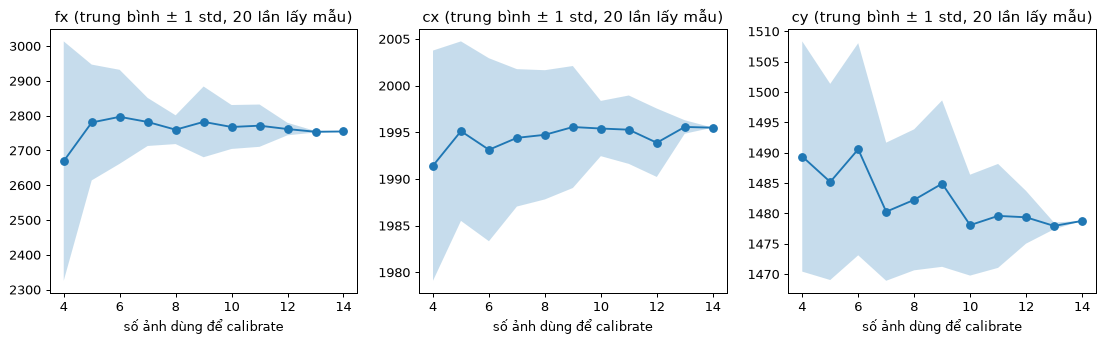

Độ lệch chuẩn của fx theo số ảnh: {4: 344.0, 5: 166.4, 6: 135.0, 7: 69.1, 8: 41.4, 9: 101.7, 10: 63.1, 11: 60.8, 12: 17.9, 13: 2.1, 14: nan}


In [11]:
rng = np.random.default_rng(0)
conv = []
for n in range(4, len(obj_k) + 1):
    for rep in range(20 if n < len(obj_k) else 1):
        idx = rng.choice(len(obj_k), n, replace=False)
        c = cal.calibrate_opencv([obj_k[j] for j in idx], [img_k[j] for j in idx], data.image_size, flags)
        conv.append(dict(n_views=n, fx=c['K'][0, 0], cx=c['K'][0, 2], cy=c['K'][1, 2], rms=c['rms']))
conv = pd.DataFrame(conv)
agg = conv.groupby('n_views').agg(['mean', 'std'])
agg.to_csv(OUT / 'convergence.csv')

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for a, col in zip(ax, ['fx', 'cx', 'cy']):
    m, s = agg[col]['mean'], agg[col]['std'].fillna(0)
    a.plot(m.index, m, 'o-'); a.fill_between(m.index, m - s, m + s, alpha=0.25)
    a.set_xlabel('số ảnh dùng để calibrate'); a.set_title(f'{col} (trung bình ± 1 std, 20 lần lấy mẫu)')
save(fig, 'convergence.png')
print('Độ lệch chuẩn của fx theo số ảnh:', agg['fx']['std'].round(1).to_dict())

## 7. Sửa méo và đo định lượng

### 7.1 Trường dịch chuyển của méo
Mỗi pixel bị ống kính kéo lệch bao xa? Tính bằng `cv2.undistortPoints` trên một lưới điểm phủ toàn khung hình.

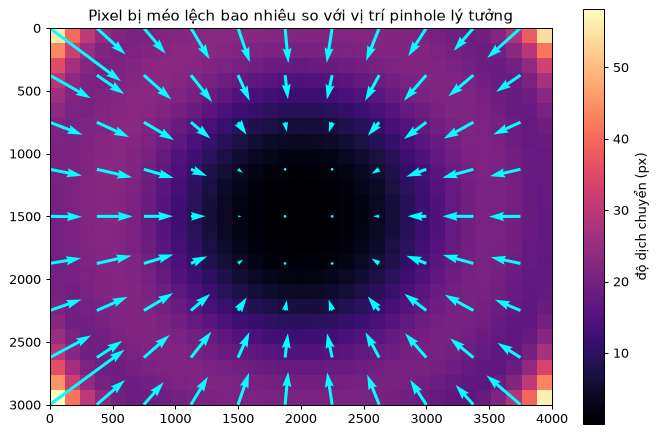

Dịch chuyển: tâm ảnh 0.0 px | trung bình 16.6 px | lớn nhất (góc ảnh) 58.2 px
Trong vùng có dữ liệu (r <= 0.84): lớn nhất 23.0 px. Ngoài vùng này (4 góc ảnh) giá trị là NGOẠI SUY của đa thức méo, kém tin cậy hơn.


In [12]:
xs, ys = np.meshgrid(np.linspace(0, W - 1, 33), np.linspace(0, H - 1, 25))
grid = np.column_stack([xs.ravel(), ys.ravel()])
und = cal.undistort_points_px(grid, K, dist)
disp = np.linalg.norm(und - grid, axis=1).reshape(xs.shape)
fig, ax = plt.subplots(figsize=(9, 6))
im = ax.imshow(disp, extent=[0, W, H, 0], cmap='magma')
plt.colorbar(im, ax=ax, label='độ dịch chuyển (px)')
step = 3
ax.quiver(xs[::step, ::step], ys[::step, ::step], (und[:, 0] - grid[:, 0]).reshape(xs.shape)[::step, ::step],
          -(und[:, 1] - grid[:, 1]).reshape(xs.shape)[::step, ::step], color='cyan')
ax.set_title('Pixel bị méo lệch bao nhiêu so với vị trí pinhole lý tưởng')
save(fig, 'distortion_field.png')
centre = disp[disp.shape[0] // 2, disp.shape[1] // 2]
print(f'Dịch chuyển: tâm ảnh {centre:.1f} px | trung bình {disp.mean():.1f} px | lớn nhất (góc ảnh) {disp.max():.1f} px')
r_grid = np.hypot(grid[:, 0] - W / 2, grid[:, 1] - H / 2) / np.hypot(W / 2, H / 2)
inside = r_grid <= r_norm.max()
print(f'Trong vùng có dữ liệu (r <= {r_norm.max():.2f}): lớn nhất {disp.ravel()[inside].max():.1f} px. '
      'Ngoài vùng này (4 góc ảnh) giá trị là NGOẠI SUY của đa thức méo, kém tin cậy hơn.')

### 7.2 Ảnh kiểm tra độc lập (không dùng để calibrate)
`getOptimalNewCameraMatrix` có tham số `alpha`: **alpha = 0** cắt để chỉ còn pixel hợp lệ, **alpha = 1** giữ toàn bộ pixel nguồn nên xuất hiện viền đen.

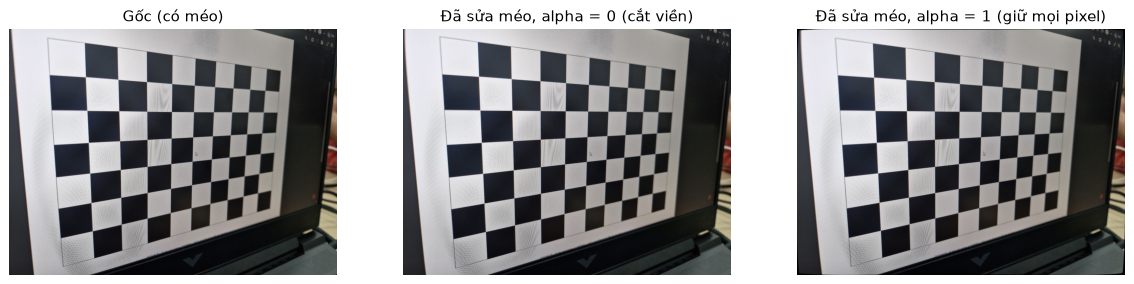

In [13]:
sample = cv2.imread(str(SAMPLE_IMG))
assert (sample.shape[1], sample.shape[0]) == data.image_size, 'Ảnh kiểm tra phải cùng độ phân giải với ảnh calibration'
u0, K0, _ = cal.undistort_image(sample, K, dist, alpha=0)
u1, K1, _ = cal.undistort_image(sample, K, dist, alpha=1)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
for a, im_, t in zip(ax, [sample, u0, u1], ['Gốc (có méo)', 'Đã sửa méo, alpha = 0 (cắt viền)', 'Đã sửa méo, alpha = 1 (giữ mọi pixel)']):
    a.imshow(rgb(im_, 900)); a.set_title(t); a.axis('off')
save(fig, 'undistort_sample.png')
_ = cv2.imwrite(str(OUT / 'sample_undistorted.jpg'), cv2.resize(u0, (1200, 900)), [cv2.IMWRITE_JPEG_QUALITY, 85])

### 7.3 Đo độ thẳng

Một đường thẳng ngoài đời qua camera pinhole lý tưởng **vẫn là đường thẳng**. Méo ống kính làm nó cong.

- Mỗi hàng và mỗi cột gồm 9 hoặc 6 góc bàn cờ thẳng hàng ngoài thực tế. Fit một đường thẳng (SVD) và đo **RMS khoảng cách vuông góc** của các góc tới đường đó.
- So sánh trước sau khi sửa méo (`undistortPoints`). Sửa méo đúng thì giá trị này phải **giảm**.
- Kiểm tra trên **ảnh độc lập** (ảnh mẫu) và trên toàn bộ ảnh calibration.

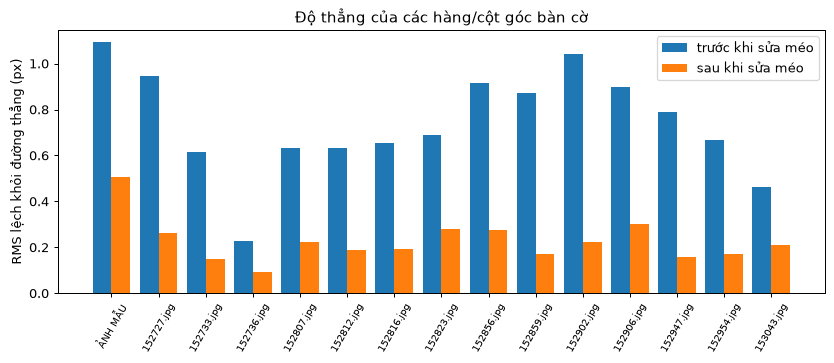

Trung bình trên ảnh calibration: 0.718 px -> 0.207 px


,image,before_px,after_px,reduction_%
0,20261021_162828.jpg (độc lập),1.09188,0.506387,53.6225
1,20261021_152727.jpg,0.948076,0.261155,72.4542
2,20261021_152733.jpg,0.615364,0.148447,75.8765


In [14]:
rows = []
ok, sc, _ = cal.detect_corners(cv2.cvtColor(sample, cv2.COLOR_BGR2GRAY), PATTERN)
if ok:
    b = cal.line_straightness(sc.reshape(-1, 2), PATTERN)
    a = cal.line_straightness(cal.undistort_points_px(sc, K, dist), PATTERN)
    rows.append(dict(image=SAMPLE_IMG.name + ' (độc lập)', before_px=b.mean(), after_px=a.mean()))
else:
    print('Không tìm thấy bàn cờ trong ảnh mẫu, bỏ qua phép đo trên ảnh độc lập.')
for f, p in zip(files_k, img_k):
    b = cal.line_straightness(p.reshape(-1, 2), PATTERN)
    a = cal.line_straightness(cal.undistort_points_px(p, K, dist), PATTERN)
    rows.append(dict(image=f, before_px=b.mean(), after_px=a.mean()))
straight = pd.DataFrame(rows)
straight['reduction_%'] = 100 * (1 - straight.after_px / straight.before_px)
straight.to_csv(OUT / 'straightness.csv', index=False)

fig, ax = plt.subplots(figsize=(11, 3.8))
x = np.arange(len(straight))
ax.bar(x - 0.2, straight.before_px, 0.4, label='trước khi sửa méo')
ax.bar(x + 0.2, straight.after_px, 0.4, label='sau khi sửa méo')
ax.set_xticks(x, [s[-10:] if 'độc lập' not in s else 'ẢNH MẪU' for s in straight.image], rotation=60, fontsize=8)
ax.set_ylabel('RMS lệch khỏi đường thẳng (px)'); ax.legend(); ax.set_title('Độ thẳng của các hàng/cột góc bàn cờ')
save(fig, 'straightness.png')
print(f"Trung bình trên ảnh calibration: {straight.before_px[int(ok):].mean():.3f} px -> {straight.after_px[int(ok):].mean():.3f} px")
straight.head(3)

### 7.4 Ảnh sàn gạch (cạnh gạch là đường thẳng thật)
So sánh vùng **góc ảnh**, nơi méo mạnh nhất. Ảnh này chỉ để quan sát định tính; phép đo định lượng nằm ở mục 7.3.

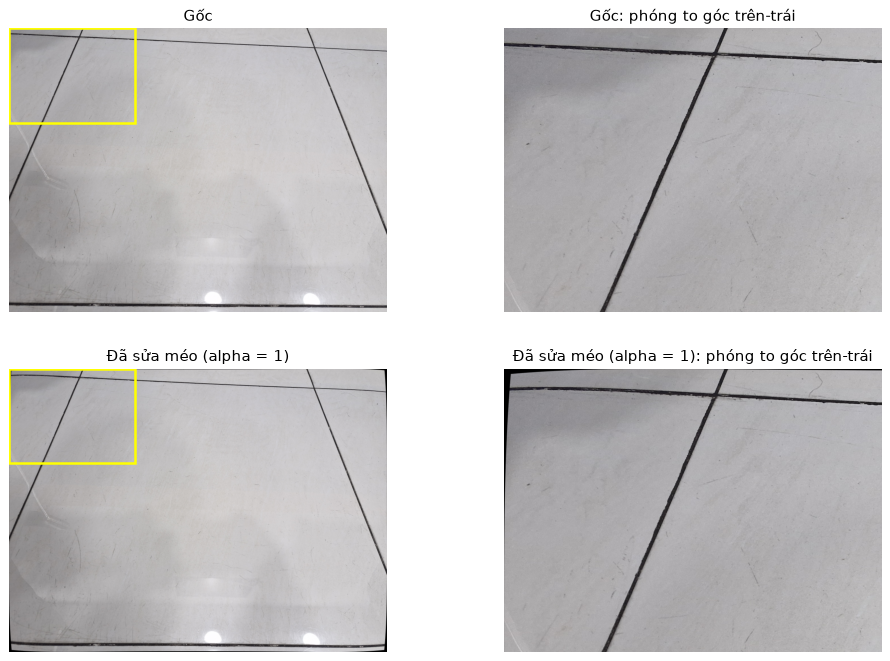

In [15]:
lines_img = cv2.imread(str(LINES_IMG))
if lines_img is None or (lines_img.shape[1], lines_img.shape[0]) != data.image_size:
    print('Bỏ qua: ảnh sàn gạch không có hoặc khác độ phân giải.')
else:
    lu, _, _ = cal.undistort_image(lines_img, K, dist, alpha=1)
    cw, ch = W // 3, H // 3
    fig, ax = plt.subplots(2, 2, figsize=(13, 9))
    for r, (im_, t) in enumerate([(lines_img, 'Gốc'), (lu, 'Đã sửa méo (alpha = 1)')]):
        ax[r, 0].imshow(rgb(im_, 1000)); ax[r, 0].set_title(t); ax[r, 0].axis('off')
        ax[r, 0].add_patch(plt.Rectangle((0, 0), 1000 / 3, 750 / 3, fill=False, ec='yellow', lw=2))
        ax[r, 1].imshow(rgb(im_[:ch, :cw])); ax[r, 1].set_title(t + ': phóng to góc trên-trái'); ax[r, 1].axis('off')
    save(fig, 'undistort_floor_tiles.png')

## 8. Lưu kết quả cho Task 3 và cho báo cáo

In [16]:
cal.save_calibration(ARTIFACT, K, dist, data.image_size, model=choice, rms=final['rms'],
                     pattern=np.array(PATTERN), square_mm=SQUARE_MM)
metrics = {
    'n_images_total': len(paths), 'n_images_detected': data.n_views, 'n_images_used': len(obj_k),
    'image_size_wh': list(data.image_size), 'pattern_inner_corners': list(PATTERN), 'square_mm': SQUARE_MM,
    'distortion_model': choice, 'K': np.round(K, 4).tolist(), 'dist': np.round(dist, 8).tolist(),
    'rms_reprojection_px': final['rms'],
    'zhang_scratch_vs_opencv_max_rel_diff': float(rel.max()),
    'holdout_rms_px_chosen_model': float(cvdf.loc[choice, 'holdout_rms_px']),
    'max_distortion_displacement_px': float(disp.max()),
    'straightness_before_after_px': [float(straight.before_px.mean()), float(straight.after_px.mean())],
}
(OUT / 'metrics.json').write_text(json.dumps(metrics, indent=2, ensure_ascii=False), encoding='utf-8')
print('Đã lưu:', ARTIFACT.relative_to(ROOT), 'và', (OUT / 'metrics.json').relative_to(ROOT))
print(json.dumps(metrics, indent=2, ensure_ascii=False))

Đã lưu: artifacts\calibration.npz và results\1A\metrics.json
{
  "n_images_total": 15,
  "n_images_detected": 15,
  "n_images_used": 14,
  "image_size_wh": [
    4000,
    3000
  ],
  "pattern_inner_corners": [
    9,
    6
  ],
  "square_mm": 18.0,
  "distortion_model": "5 - k1,k2,p1,p2,k3",
  "K": [
    [
      2754.6455,
      0.0,
      1995.5031
    ],
    [
      0.0,
      2754.7902,
      1478.7785
    ],
    [
      0.0,
      0.0,
      1.0
    ]
  ],
  "dist": [
    0.1437605,
    -0.42841099,
    -0.0003473,
    -0.000345,
    0.35940243
  ],
  "rms_reprojection_px": 0.45811331032087543,
  "zhang_scratch_vs_opencv_max_rel_diff": 2.342938557129987e-08,
  "holdout_rms_px_chosen_model": 0.5189291834831238,
  "max_distortion_displacement_px": 58.235185662049176,
  "straightness_before_after_px": [
    0.7426881340024104,
    0.22727630475905797
  ]
}


In [17]:
# Tóm tắt tự động: số liệu lấy trực tiếp từ kết quả chạy ở trên, không điền tay
print(f'''TÓM TẮT TASK 1A
- {data.n_views}/{len(paths)} ảnh bàn cờ phát hiện đủ {len(data.object_points[0])} góc; dùng {len(obj_k)} ảnh, độ phân giải {W}x{H}.
- Zhang tự cài khớp OpenCV: chênh lệch tương đối lớn nhất của fx, fy, cx, cy = {rel.max():.1e}.
- Mô hình méo chọn bằng cross-validation: "{choice}" (hold-out RMS {cvdf.loc[choice, "holdout_rms_px"]:.3f} px;
  pinhole thuần: {cvdf.holdout_rms_px.iloc[0]:.3f} px).
- K: fx = {K[0,0]:.1f}, fy = {K[1,1]:.1f}, cx = {K[0,2]:.1f}, cy = {K[1,2]:.1f} px; góc nhìn ngang ~{fov_x:.1f} độ.
- RMS reprojection error cuối cùng: {final["rms"]:.3f} px.
- Méo dịch pixel tối đa {disp.max():.1f} px ở góc ảnh; độ lệch khỏi đường thẳng giảm từ
  {straight.before_px.mean():.3f} px xuống {straight.after_px.mean():.3f} px sau khi sửa méo.''')

TÓM TẮT TASK 1A
- 15/15 ảnh bàn cờ phát hiện đủ 54 góc; dùng 14 ảnh, độ phân giải 4000x3000.
- Zhang tự cài khớp OpenCV: chênh lệch tương đối lớn nhất của fx, fy, cx, cy = 2.3e-08.
- Mô hình méo chọn bằng cross-validation: "5 - k1,k2,p1,p2,k3" (hold-out RMS 0.519 px;
  pinhole thuần: 2.317 px).
- K: fx = 2754.6, fy = 2754.8, cx = 1995.5, cy = 1478.8 px; góc nhìn ngang ~72.0 độ.
- RMS reprojection error cuối cùng: 0.458 px.
- Méo dịch pixel tối đa 58.2 px ở góc ảnh; độ lệch khỏi đường thẳng giảm từ
  0.743 px xuống 0.227 px sau khi sửa méo.


## 9. Nhận xét và hạn chế

- **K chỉ đúng cho đúng cấu hình đã calibrate:** cùng điện thoại, ống kính chính, độ phân giải 4000×3000, không zoom. Nếu ảnh được resize, phải nhân $f_x, f_y, c_x, c_y$ theo cùng tỉ lệ. Ảnh tải từ Internet (ví dụ dataset trái cây Kaggle ở Task 2) **không được** sửa méo bằng K này.
- **Bàn cờ hiển thị trên màn hình laptop:** màn hình phẳng nên dùng được, nhưng gây moiré, và cạnh ô thực tế phụ thuộc mức zoom của màn hình. `SQUARE_MM` chỉ ảnh hưởng **đơn vị của t**, không ảnh hưởng K hay dist. Muốn đo khoảng cách thật thì cần đo lại cạnh ô bằng thước.
- **Điện thoại có tự động lấy nét (autofocus)**, nên tiêu cự thay đổi nhẹ theo khoảng cách chụp. Đây là một nguồn sai số chưa mô hình hoá.
- **Bộ xử lý ảnh (ISP)** của điện thoại thường đã bù méo một phần, nên méo còn lại có thể là méo bậc cao. Đó là lý do mục 5 dùng dữ liệu để chọn số hệ số thay vì giả định.
- **Cải tiến khả thi:** in bàn cờ ra giấy cứng hoặc dùng bảng ChArUco; chụp thêm ảnh có góc bàn cờ sát mép khung hình (xem biểu đồ độ phủ); khoá lấy nét khi chụp.